In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
data = pd.read_csv(r"D:\retail-analytics-project\data\processed\cleaned_online_retail.csv")
data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,isNonProduct,IsValidSale,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False,True,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,True,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,True,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False,True,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False,True,30.0


In [5]:
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
data.dtypes

Invoice                 object
StockCode               object
Description             object
Quantity                 int64
InvoiceDate     datetime64[ns]
Price                  float64
Customer ID            float64
Country                 object
IsCancelled               bool
isNonProduct              bool
IsValidSale               bool
TotalPrice             float64
dtype: object

In [6]:
data['YearMonth'] = data['InvoiceDate'].dt.to_period('M')
data[['InvoiceDate', 'YearMonth']].head()

,InvoiceDate,YearMonth
0,2009-12-01 07:45:00,2009-12
1,2009-12-01 07:45:00,2009-12
2,2009-12-01 07:45:00,2009-12
3,2009-12-01 07:45:00,2009-12
4,2009-12-01 07:45:00,2009-12


In [7]:
monthly_sales = data[data['IsValidSale']].groupby('YearMonth')['TotalPrice'].sum().reset_index()
monthly_sales

,YearMonth,TotalPrice
0,2009-12,798747.030
1,2010-01,612605.502
2,2010-02,538147.646
3,2010-03,762148.531
4,2010-04,646873.062
5,2010-05,643904.880
6,2010-06,697864.870
7,2010-07,633899.420
8,2010-08,674887.890
9,2010-09,869772.161


## Load Cleaned Data & Prepare for Time-Based Analysis

Loaded the cleaned dataset (`cleaned_online_retail.csv`) from Day 2. Re-converted `InvoiceDate` 
to a proper datetime type (CSV export/reload always reverts datetime columns back to plain text, 
so this must be redone each time a cleaned CSV is loaded).

Created `YearMonth` by collapsing each transaction's timestamp down to just its year-month 
(e.g. 2010-03), to allow grouping transactions by month instead of by exact date/time.

Aggregated total revenue per month (`monthly_sales`), filtering to `IsValidSale == True` only, 
so cancellations, non-product entries (postage/adjustments), and zero-price rows don't distort 
the revenue trend.

**Goal:** answer "how does our revenue trend over time?" — chose monthly (not daily) granularity 
since daily data would be too noisy/volatile to reveal meaningful seasonal patterns.

In [17]:
data['InvoiceDate'].max()

Timestamp('2010-12-09 20:01:00')

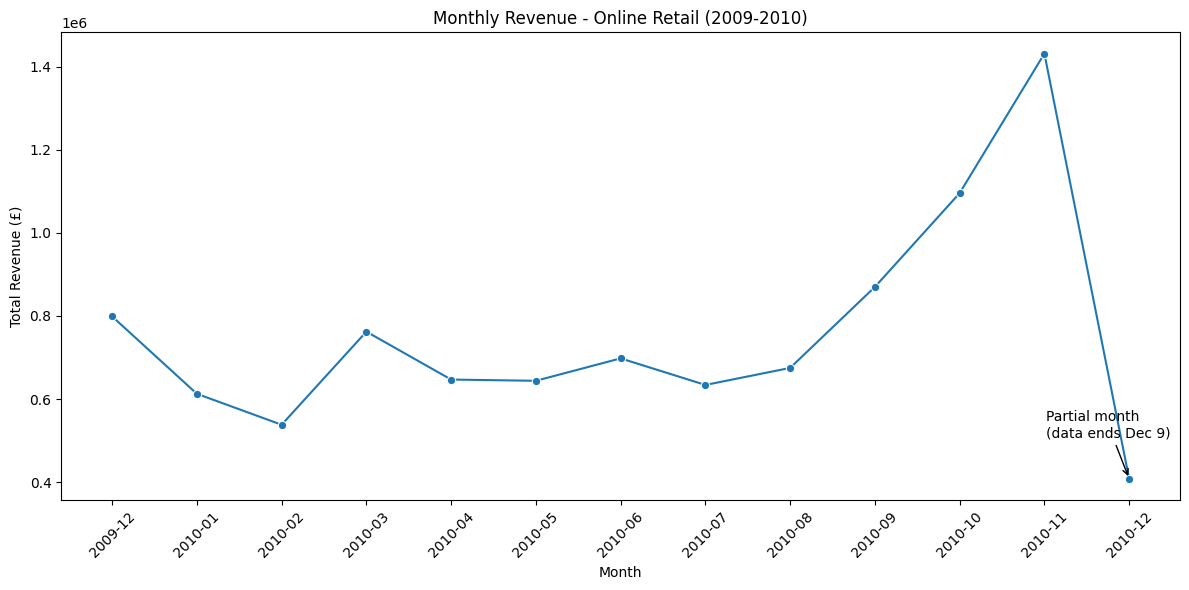

In [18]:
plt.figure(figsize=(12,6))
sns.lineplot(data=monthly_sales, x='YearMonth', y='TotalPrice', marker='o')
plt.xticks(rotation=45)
plt.title('Monthly Revenue - Online Retail (2009-2010)')
plt.xlabel('Month')
plt.ylabel('Total Revenue (£)')

plt.annotate('Partial month\n(data ends Dec 9)', 
             xy=('2010-12', monthly_sales['TotalPrice'].iloc[-1]), 
             xytext=(-60, 30), textcoords='offset points',
             arrowprops=dict(arrowstyle='->'))

plt.tight_layout()
plt.show()

Plotted total revenue by month as a line chart, since a line chart best shows trend/direction 
over ordered time periods.

The chart initially appeared to show a sharp revenue collapse in December 2010. Investigated 
further by checking `data['InvoiceDate'].max()`, which showed the dataset's last recorded 
transaction is **9 December 2010** — meaning December is a partial month (9 of 31 days), not 
a real decline. Annotated the chart to flag this rather than excluding the data point, to keep 
the chart transparent and avoid misrepresenting an incomplete period as a genuine trend.

**Business takeaway:** revenue climbs steadily from August through November, consistent with 
pre-holiday-season buying behavior, before the partial December cutoff. This is a genuine, 
checked insight — not an assumption.

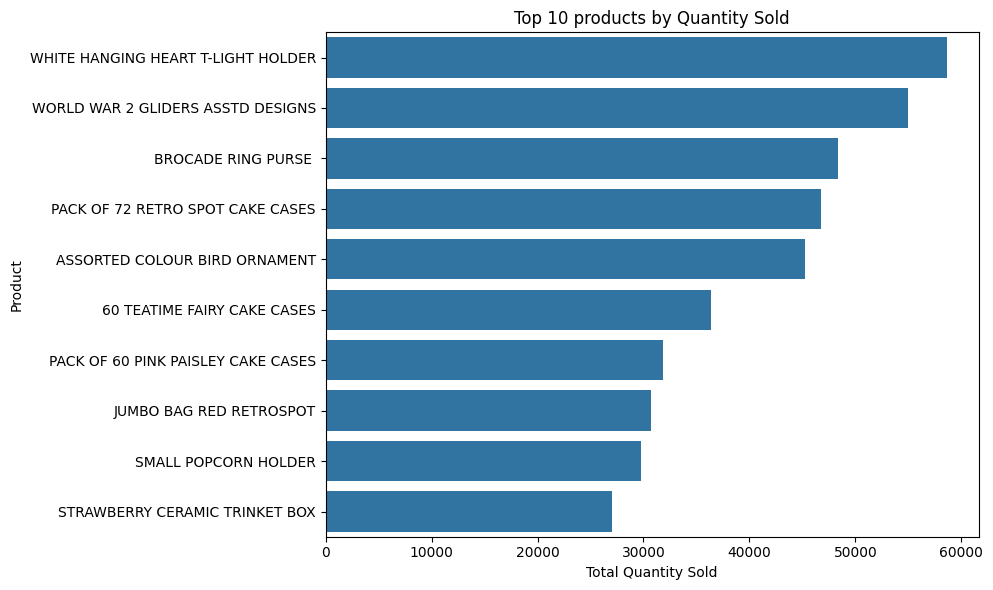

In [19]:
top_products_qty = (data[data['IsValidSale']].groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(10,6))
sns.barplot(x=top_products_qty.values, y=top_products_qty.index, orient='h')
plt.title('Top 10 products by Quantity Sold')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

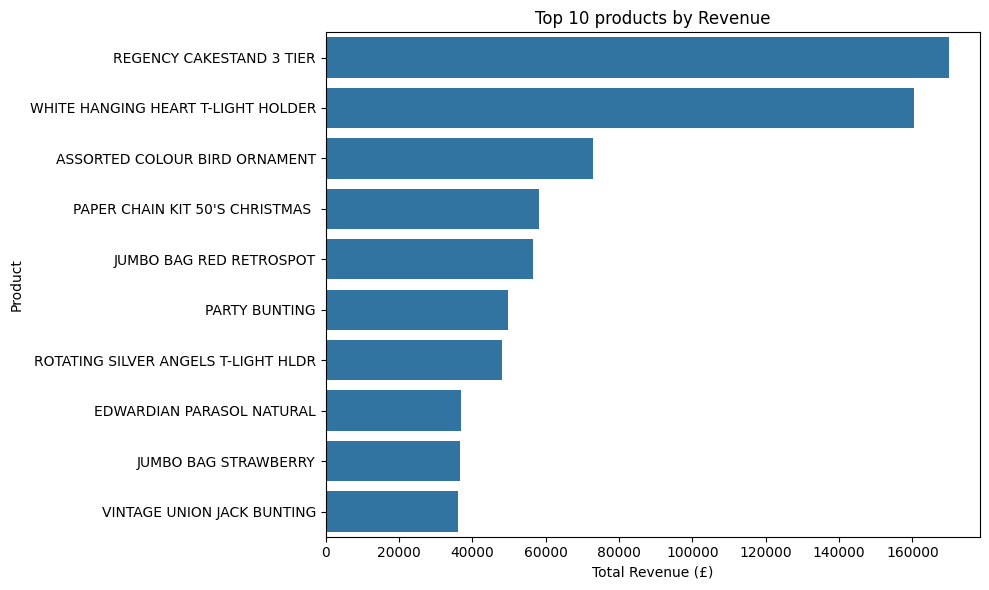

In [20]:
top_products_revenue = (data[data['IsValidSale']].groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(10,6))
sns.barplot(x=top_products_revenue.values, y=top_products_revenue.index, orient='h')
plt.title('Top 10 products by Revenue')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

 Top Products — Quantity vs. Revenue

Computed top 10 products two ways: by total quantity sold, and by total revenue generated. 
Both filtered to `IsValidSale == True` only.

The two rankings differ meaningfully — e.g. "Regency Cakestand 3 Tier" is the #1 product by 
revenue but doesn't appear in the top 10 by quantity, indicating a lower-volume, higher-price 
item. This shows "best-selling" is ambiguous without specifying which metric matters for the 
decision at hand.

Note: this dataset has no cost data, so revenue (not profit) is the correct term here — profit 
margin per product cannot be determined from what's available.

**Business takeaway:** stocking/promotion decisions should consider both volume and revenue 
contribution, not just one metric in isolation.

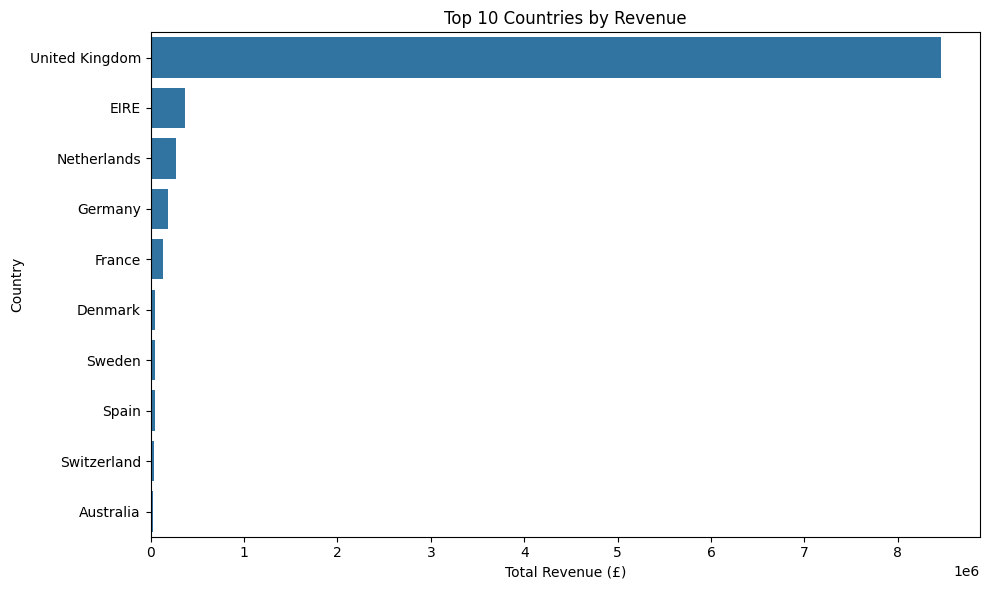

In [21]:
top_countries = (data[data['IsValidSale']]
                  .groupby('Country')['TotalPrice']
                  .sum()
                  .sort_values(ascending=False)
                  .head(10))

plt.figure(figsize=(10,6))
sns.barplot(x=top_countries.values, y=top_countries.index, orient='h')
plt.title('Top 10 Countries by Revenue')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

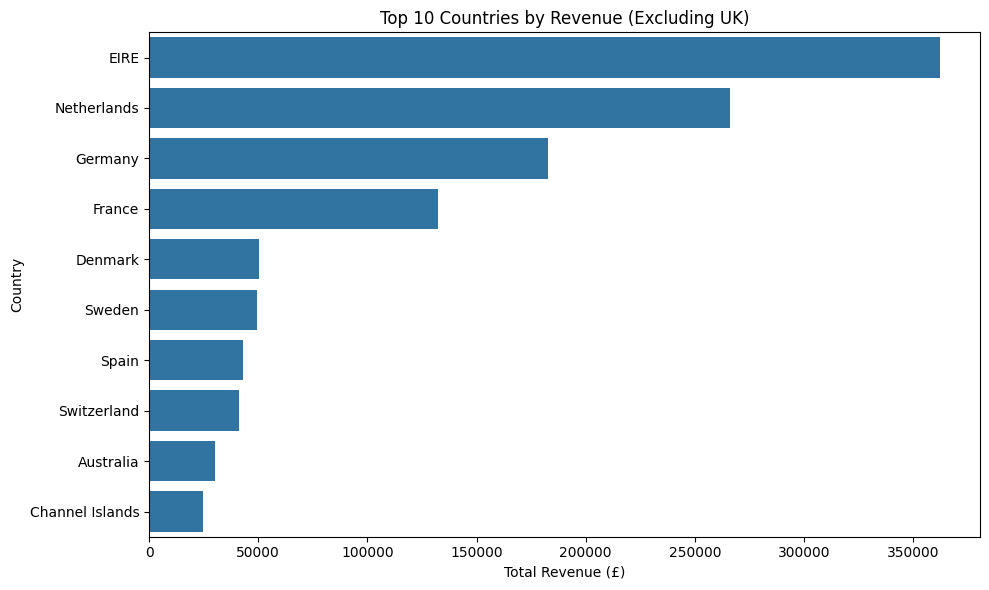

In [22]:
top_countries_excl_uk = (data[(data['IsValidSale']) & (data['Country'] != 'United Kingdom')]
                          .groupby('Country')['TotalPrice']
                          .sum()
                          .sort_values(ascending=False)
                          .head(10))

plt.figure(figsize=(10,6))
sns.barplot(x=top_countries_excl_uk.values, y=top_countries_excl_uk.index, orient='h')
plt.title('Top 10 Countries by Revenue (Excluding UK)')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

 Top Countries by Revenue

Computed total revenue by country, filtered to `IsValidSale == True` only.

United Kingdom dominates (~£8.5M), which is expected — this is a UK-based retailer, and the 
initial chart made every other country's bar nearly invisible by comparison. Built a second 
chart excluding UK to reveal the actual ranking among international markets.

**Business takeaway:** outside the UK, EIRE (Ireland), Netherlands, and Germany are the top 
revenue-generating markets — worth considering for targeted marketing or international 
logistics investment, since they clearly outperform other international markets by a wide margin.